# Classificador de imagens com CNN, versão 2

Evolução da versão 1 com três técnicas para reduzir o overfitting:

- **Aumento de dados** (`RandomFlip`, `RandomTranslation`), aplicado só no treino;
- **Batch normalization**, para estabilizar o treino;
- **Dropout**, desligando neurônios aleatoriamente durante o treino.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

tf.keras.utils.set_random_seed(42)
(X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()
y_train_full, y_test = y_train_full.ravel(), y_test.ravel()

CLASSES = ["avião", "automóvel", "pássaro", "gato", "cervo", "cachorro", "sapo", "cavalo", "navio", "caminhão"]

X_train_full = X_train_full.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Validação separada do treino, para acompanhar o overfitting sem tocar no teste.
X_train, X_val = X_train_full[:45000], X_train_full[45000:]
y_train, y_val = y_train_full[:45000], y_train_full[45000:]
print(X_train.shape, X_val.shape, X_test.shape)

I0000 00:00:1792892112.415110  183382 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792892112.460005  183382 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1792892113.663352  183382 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


(45000, 32, 32, 3) (5000, 32, 32, 3) (10000, 32, 32, 3)


## 1. Arquitetura

In [2]:
model = tf.keras.Sequential(
    [
        tf.keras.Input(shape=(32, 32, 3)),
        # Aumento de dados: ativo só durante o treino.
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomTranslation(0.1, 0.1),
        tf.keras.layers.Conv2D(32, (3, 3), padding="same", use_bias=False),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation("relu"),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Conv2D(64, (3, 3), padding="same", use_bias=False),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Activation("relu"),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(10, activation="softmax"),
    ],
    name="cnn_v2",
)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

E0000 00:00:1792892116.322721  183382 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1792892116.323037  183584 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1792892116.342599  183382 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Model: "cnn_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 32, 32, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,386 (2.08 MB)

 Trainable params: 545,194 (2.08 MB)

 Non-trainable params: 192 (768.00 B)

## 2. Treino

Com mais regularização, o treino converge mais devagar: usamos mais épocas.

In [3]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=12,
    batch_size=64,
    verbose=0,
)

W0000 00:00:1792892116.640569  183382 cpu_allocator_impl.cc:82] Allocation of 552960000 exceeds 10% of free system memory.


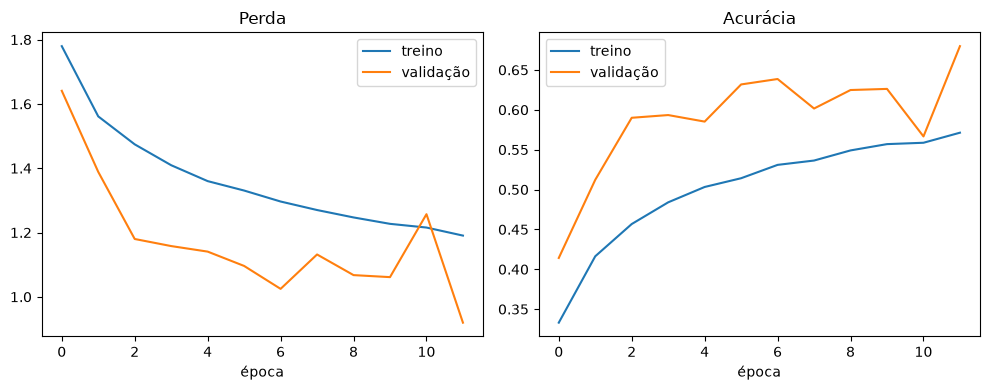

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history.history["loss"], label="treino")
axes[0].plot(history.history["val_loss"], label="validação")
axes[0].set_title("Perda")
axes[0].set_xlabel("época")
axes[0].legend()
axes[1].plot(history.history["accuracy"], label="treino")
axes[1].plot(history.history["val_accuracy"], label="validação")
axes[1].set_title("Acurácia")
axes[1].set_xlabel("época")
axes[1].legend()
plt.tight_layout()
plt.show()

## 3. Avaliação no conjunto de teste

A camada de aumento de dados é desligada automaticamente na inferência.

In [5]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Teste: perda={test_loss:.4f}  acurácia={test_accuracy:.4f}")

Teste: perda=0.9446  acurácia=0.6656


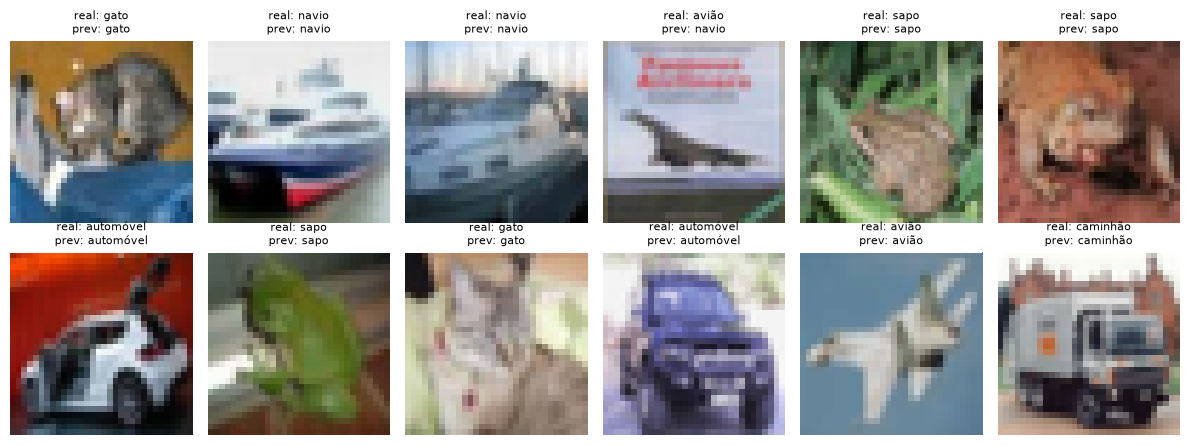

In [6]:
probs = model.predict(X_test[:12], verbose=0)
fig, axes = plt.subplots(2, 6, figsize=(12, 4.5))
for ax, img, prob, true in zip(axes.ravel(), X_test[:12], probs, y_test[:12]):
    ax.imshow(img)
    ax.set_title(f"real: {CLASSES[true]}\nprev: {CLASSES[prob.argmax()]}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()